Based on the material assume different thicknesses

In [ ]:
type "single", "triple"
inner diameter
air_gaps

each layer:
thickness_w_m
density_w_kg_m3
cp_w_J_kg_K
K_w_W_m_K
epsilon_w

film_w
roughness_m


In [ ]:
num_segments
orientation
fittings
humidity_ratio

In [ ]:
vent type
height_ft (the height of the vent)
z-ft (where the vent starts vertically (i.e.: distance from the ground to start of vent))
orientation
fittings
num_segments (defaulted)
air temp

In [1]:
import numpy as np
import matplotlib.pyplot as plt 
def _default_inlet_temp( t, T_ambient=293.15, T_max=773.15, tau=300):
    """
    Models the inlet gas temperature entering the chimney as a function of time.
    This is the temperature of the flue gas entering the bottom of the chimney,
    NOT the fire temperature itself.
    
    Parameters:
        t (float or array): Time in seconds.
        T_ambient (float): Ambient temperature in Kelvin (default is 20°C = 293.15 K).
        T_max (float): Maximum inlet gas temperature in Kelvin (default is 500°C = 773.15 K).
        tau (float): Characteristic time constant in seconds. Controls how fast it heats up.
    
    Returns:
        float or array: Inlet gas temperature in Kelvin at time t.
    """
    return T_ambient + (T_max - T_ambient) * (1 - np.exp(-t / tau))
def _default_inlet_temp_fire( t_sec: float) -> float:
    """Calculate inlet gas temperature based on fire curve.
    
    Args:
        t_sec: Time in seconds
        
    Returns:
        Temperature in Kelvin
    """
    T_fire_C = 20 + 345 * np.log10(8 * ((t_sec + 1.5) / 60) + 1)
    T_flue_C = 0.5 * T_fire_C   # empirical scaling
    T_flue_K = T_flue_C + 273.15
    return min(T_flue_K, 800) 

In [4]:
olds=[]
news=[]
for t_sec in range(0,1201):
    olds.append(_default_inlet_temp_fire(t_sec))
    news.append(_default_inlet_temp(t_sec))

Text(0.5, 0, 'Time (m)')

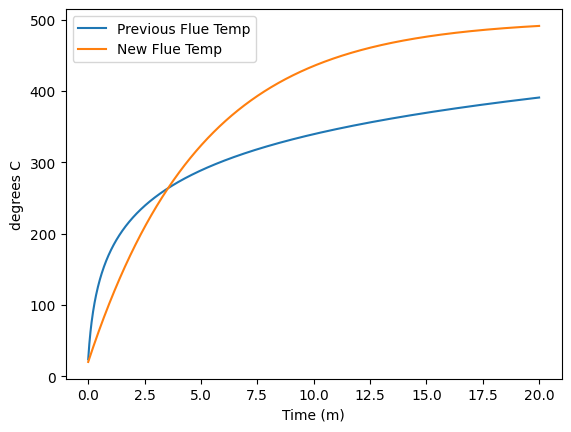

In [7]:
plt.plot([i/60 for i in range(0,1201)],[i-273.15 for i in olds],label='Previous Flue Temp')
plt.plot([i/60 for i in range(0,1201)],[i-273.15 for i in news],label='New Flue Temp')
plt.legend()
plt.ylabel('degrees C')
plt.xlabel('Time (m)')